In [40]:
! python3 -m pip install pandas openpyxl matplotlib

Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 250 kB 17.9 MB/s eta 0:00:01
     |████████████████████████████████| 7.9 MB 36.6 MB/s eta 0:00:01
     |████████████████████████████████| 265 kB 56.5 MB/s eta 0:00:01
  Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
     |████████████████████████████████| 126 kB 57.5 MB/s eta 0:00:01
     |████████████████████████████████| 65 kB 14.6 MB/s eta 0:00:01
     |████████████████████████████████| 2.4 MB 23.6 MB/s eta 0:00:01
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.


In [ ]:
from pathlib import Path

import pandas as pd

here = Path.cwd()
candidates = [
    here / "SR2019.csv",
    here / "311 service request" / "SR2019.csv",
]
csv_path = next(path for path in candidates if path.exists())

df = pd.read_csv(csv_path)
df.head()

In [ ]:
label_candidates = [
    here / "311_SR_label_to_keep.csv",
    here / "311 service request" / "311_SR_label_to_keep.csv",
]
label_path = next(path for path in label_candidates if path.exists())

labels = pd.read_csv(label_path)
labels

## SR 2019

In [ ]:
sr_2019 = df.merge(
    labels,
    left_on="Service Request Type",
    right_on="Service type to keep",
    how="inner",
)
sr_2019 = sr_2019[sr_2019["Status"] == "Closed"]
sr_2019

In [ ]:
created = pd.to_datetime(sr_2019["Creation Date"])
hour_12 = created.dt.strftime("%I").str.lstrip("0")
period = created.dt.strftime("%p").str.lower().str.replace("m", ".m.", regex=False)

sr_2019_flood = sr_2019.copy()
sr_2019_flood["month"] = created.dt.month
sr_2019_flood["day"] = created.dt.day
sr_2019_flood["hour"] = hour_12 + " " + period
sr_2019_flood[["Creation Date", "month", "day", "hour"]].head()

In [ ]:
import matplotlib.pyplot as plt

request_types = labels["Service type to keep"].tolist()
counts = (
    sr_2019_flood.groupby(["Ward", "month", "Service Request Type"])
    .size()
    .unstack("Service Request Type", fill_value=0)
    .reindex(columns=request_types, fill_value=0)
)
shares = counts.div(counts.sum(axis=1), axis=0).fillna(0) * 100

def ward_number(name):
    return int(name.rsplit("(", 1)[1].rstrip(")"))

wards = sorted(sr_2019_flood["Ward"].unique(), key=ward_number)
months = list(range(1, 13))
colors = ["#4C78A8", "#F58518", "#54A24B", "#E45756", "#72B7B2", "#B279A2"]

fig, axes = plt.subplots(5, 5, figsize=(18, 16), sharex=True, sharey=True)
axes = axes.ravel()

for ax, ward in zip(axes, wards):
    ward_shares = shares.loc[ward].reindex(months, fill_value=0)
    bottom = None
    for request_type, color in zip(request_types, colors):
        values = ward_shares[request_type].to_numpy()
        ax.bar(
            months,
            values,
            bottom=0 if bottom is None else bottom,
            color=color,
            width=0.85,
            label=request_type,
        )
        bottom = values if bottom is None else bottom + values
    ax.set_title(ward, fontsize=8)
    ax.set_xticks(months)
    ax.set_ylim(0, 100)

for ax in axes[len(wards) :]:
    ax.axis("off")

handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.02))
fig.suptitle("Share of closed flooding requests by ward and month", y=1.06)
fig.supxlabel("Month")
fig.supylabel("Share of requests (%)")
fig.tight_layout()
plt.show()

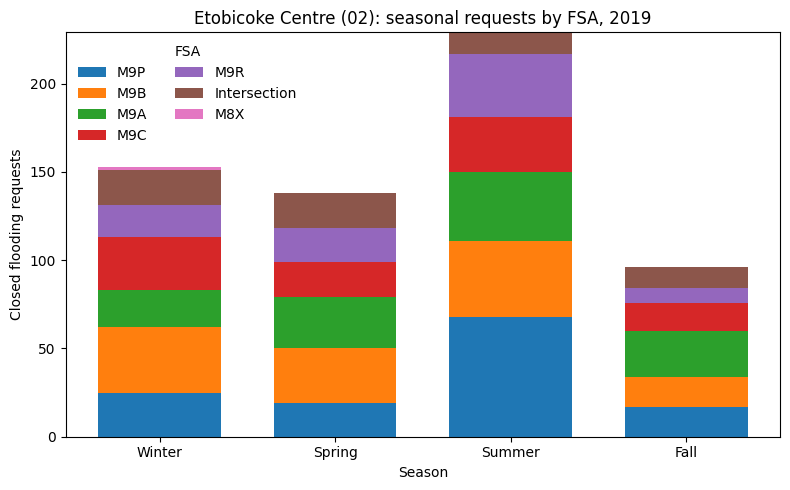

In [97]:
import matplotlib.pyplot as plt

ward_id =2
seasons = ["Winter", "Spring", "Summer", "Fall"]
season_by_month = {
    12: "Winter",
    1: "Winter",
    2: "Winter",
    3: "Spring",
    4: "Spring",
    5: "Spring",
    6: "Summer",
    7: "Summer",
    8: "Summer",
    9: "Fall",
    10: "Fall",
    11: "Fall",
}

ward_name = next(name for name in sr_2019_flood["Ward"].unique() if ward_number(name) == ward_id)
ward_rows = sr_2019_flood[sr_2019_flood["Ward"] == ward_name].copy()
ward_rows["FSA"] = ward_rows["First 3 Chars of Postal Code"].fillna("Unknown")
ward_rows["season"] = ward_rows["month"].map(season_by_month)

fsa_order = ward_rows["FSA"].value_counts().index.tolist()
fsa_counts = (
    ward_rows.groupby(["season", "FSA"])
    .size()
    .unstack("FSA", fill_value=0)
    .reindex(index=seasons, columns=fsa_order, fill_value=0)
)

colors = plt.cm.tab10.colors
fig, ax = plt.subplots(figsize=(8, 5))
bottom = None
for fsa, color in zip(fsa_order, colors):
    values = fsa_counts[fsa].to_numpy()
    ax.bar(
        seasons,
        values,
        bottom=0 if bottom is None else bottom,
        color=color,
        width=0.7,
        label=fsa,
    )
    bottom = values if bottom is None else bottom + values

ax.set_xlabel("Season")
ax.set_ylabel("Closed flooding requests")
ax.set_title(f"{ward_name}: seasonal requests by FSA, 2019")
ax.legend(title="FSA", ncol=2, frameon=False)
fig.tight_layout()
plt.show()


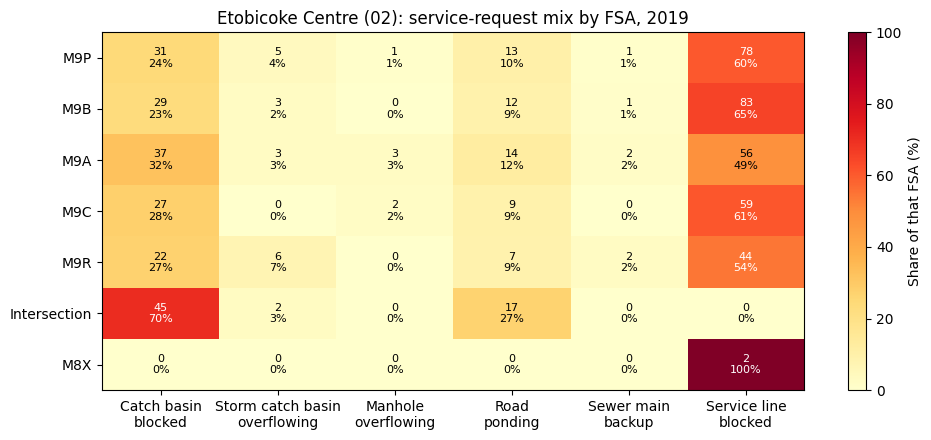

In [98]:
import matplotlib.pyplot as plt

request_types = labels["Service type to keep"].tolist()
short_labels = [
    "Catch basin\nblocked",
    "Storm catch basin\noverflowing",
    "Manhole\noverflowing",
    "Road\nponding",
    "Sewer main\nbackup",
    "Service line\nblocked",
]

counts = (
    ward_rows.groupby(["FSA", "Service Request Type"])
    .size()
    .unstack("Service Request Type", fill_value=0)
    .reindex(index=fsa_order, columns=request_types, fill_value=0)
)
shares = counts.div(counts.sum(axis=1), axis=0).fillna(0) * 100

fig, ax = plt.subplots(figsize=(10, 4.5))
image = ax.imshow(shares.to_numpy(), cmap="YlOrRd", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(short_labels)))
ax.set_xticklabels(short_labels)
ax.set_yticks(range(len(counts.index)))
ax.set_yticklabels(counts.index)
for i in range(shares.shape[0]):
    for j in range(shares.shape[1]):
        count = int(counts.iloc[i, j])
        share = shares.iloc[i, j]
        ax.text(
            j,
            i,
            f"{count}\n{share:.0f}%",
            ha="center",
            va="center",
            color="white" if share > 50 else "black",
            fontsize=8,
        )
ax.set_title(f"{ward_name}: service-request mix by FSA, 2019")
fig.colorbar(image, ax=ax, label="Share of that FSA (%)")
fig.tight_layout()
plt.show()

In [95]:
shares

Service Request Type,Catch Basin - Blocked / Flooding,Catch basin (Storm) - Overflowing,Maintenance Hole - Overflowing,Road Water Ponding,Sewer main-Backup,Sewer Service Line-Blocked
FSA,,,,,,
M9W,17.821782,5.445545,3.960396,7.425743,0.49505,64.851485
M9V,20.833333,0.833333,2.500000,8.333333,0.00000,67.500000
M9R,43.750000,1.562500,3.125000,10.937500,0.00000,40.625000
M9P,16.666667,0.000000,0.000000,10.000000,0.00000,73.333333
Intersection,60.000000,5.000000,0.000000,25.000000,0.00000,10.000000


In [ ]:
import matplotlib.pyplot as plt

request_types = labels["Service type to keep"].tolist()
volume_counts = (
    sr_2019_flood.groupby(["Ward", "month", "Service Request Type"])
    .size()
    .unstack("Service Request Type", fill_value=0)
    .reindex(columns=request_types, fill_value=0)
)

def ward_number(name):
    return int(name.rsplit("(", 1)[1].rstrip(")"))

wards = sorted(sr_2019_flood["Ward"].unique(), key=ward_number)
months = list(range(1, 13))
colors = ["#4C78A8", "#F58518", "#54A24B", "#E45756", "#72B7B2", "#B279A2"]

fig, axes = plt.subplots(5, 5, figsize=(18, 16), sharex=True, sharey=True)
axes = axes.ravel()

for ax, ward in zip(axes, wards):
    ward_counts = volume_counts.loc[ward].reindex(months, fill_value=0)
    bottom = None
    for request_type, color in zip(request_types, colors):
        values = ward_counts[request_type].to_numpy()
        ax.bar(
            months,
            values,
            bottom=0 if bottom is None else bottom,
            color=color,
            width=0.85,
            label=request_type,
        )
        bottom = values if bottom is None else bottom + values
    ax.set_title(ward, fontsize=8)
    ax.set_xticks(months)

for ax in axes[len(wards) :]:
    ax.axis("off")

handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.02))
fig.suptitle("Closed flooding requests by ward and month", y=1.06)
fig.supxlabel("Month")
fig.supylabel("Number of requests")
fig.tight_layout()
plt.show()

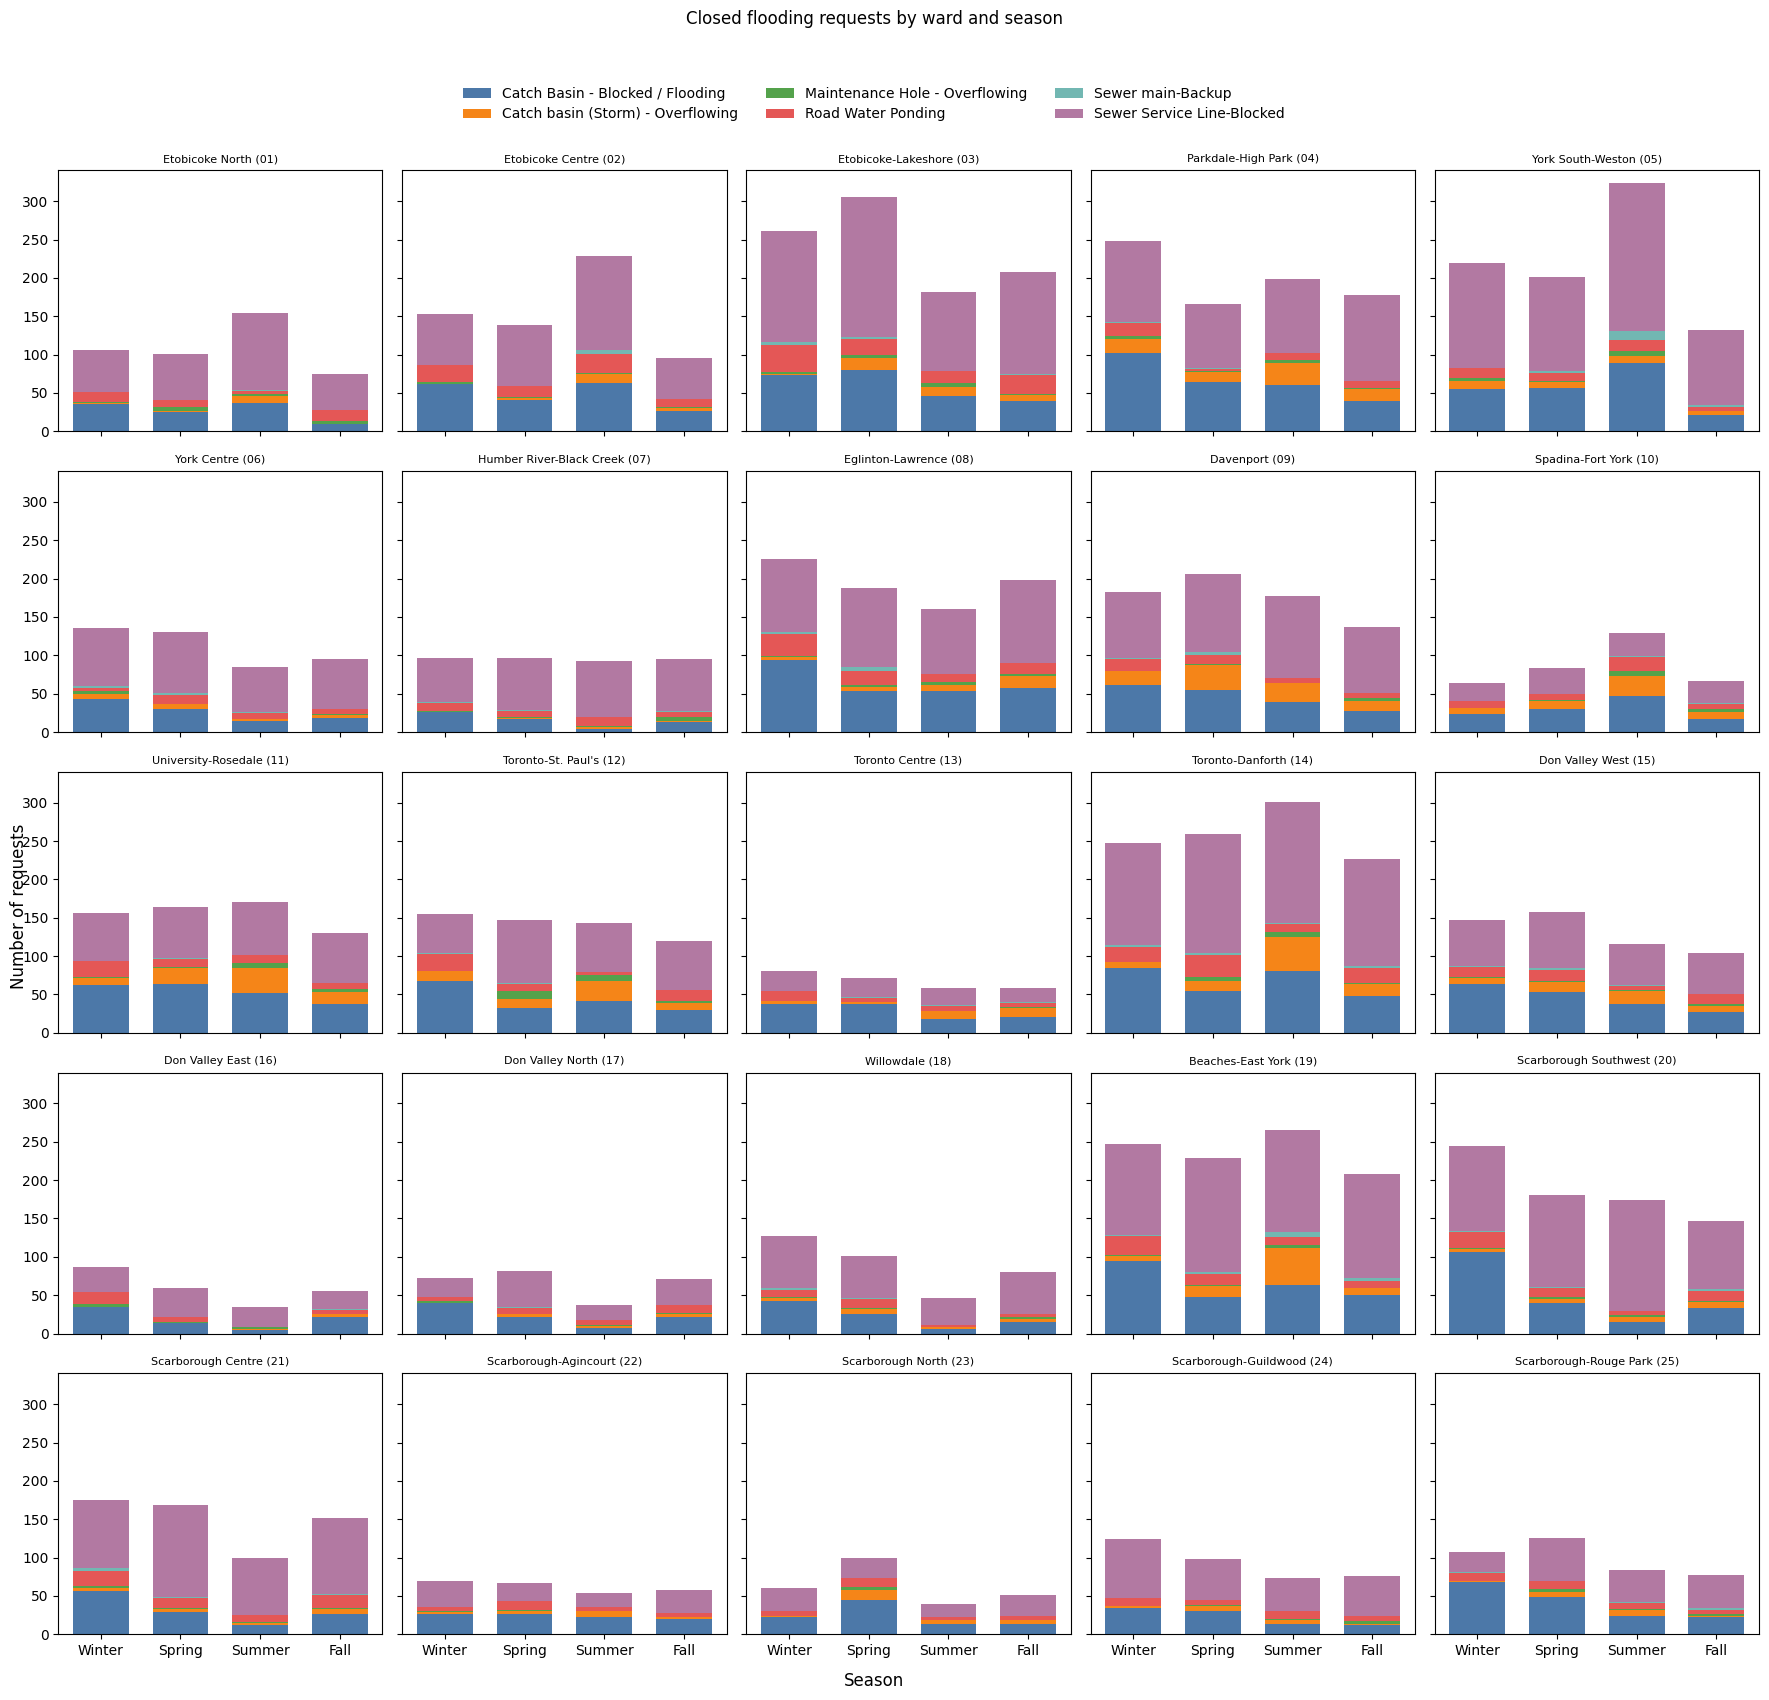

In [59]:
import matplotlib.pyplot as plt

request_types = labels["Service type to keep"].tolist()
colors = ["#4C78A8", "#F58518", "#54A24B", "#E45756", "#72B7B2", "#B279A2"]

def ward_number(name):
    return int(name.rsplit("(", 1)[1].rstrip(")"))

wards = sorted(sr_2019_flood["Ward"].unique(), key=ward_number)

season_by_month = {
    12: "Winter",
    1: "Winter",
    2: "Winter",
    3: "Spring",
    4: "Spring",
    5: "Spring",
    6: "Summer",
    7: "Summer",
    8: "Summer",
    9: "Fall",
    10: "Fall",
    11: "Fall",
}
seasons = ["Winter", "Spring", "Summer", "Fall"]

seasonal = sr_2019_flood.copy()
seasonal["season"] = seasonal["month"].map(season_by_month)
season_counts = (
    seasonal.groupby(["Ward", "season", "Service Request Type"])
    .size()
    .unstack("Service Request Type", fill_value=0)
    .reindex(columns=request_types, fill_value=0)
)

fig, axes = plt.subplots(5, 5, figsize=(18, 16), sharex=True, sharey=True)
axes = axes.ravel()

for ax, ward in zip(axes, wards):
    ward_counts = season_counts.loc[ward].reindex(seasons, fill_value=0)
    bottom = None
    for request_type, color in zip(request_types, colors):
        values = ward_counts[request_type].to_numpy()
        ax.bar(
            seasons,
            values,
            bottom=0 if bottom is None else bottom,
            color=color,
            width=0.7,
            label=request_type,
        )
        bottom = values if bottom is None else bottom + values
    ax.set_title(ward, fontsize=8)

for ax in axes[len(wards) :]:
    ax.axis("off")

handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.02))
fig.suptitle("Closed flooding requests by ward and season", y=1.06)
fig.supxlabel("Season")
fig.supylabel("Number of requests")
fig.tight_layout()
plt.show()

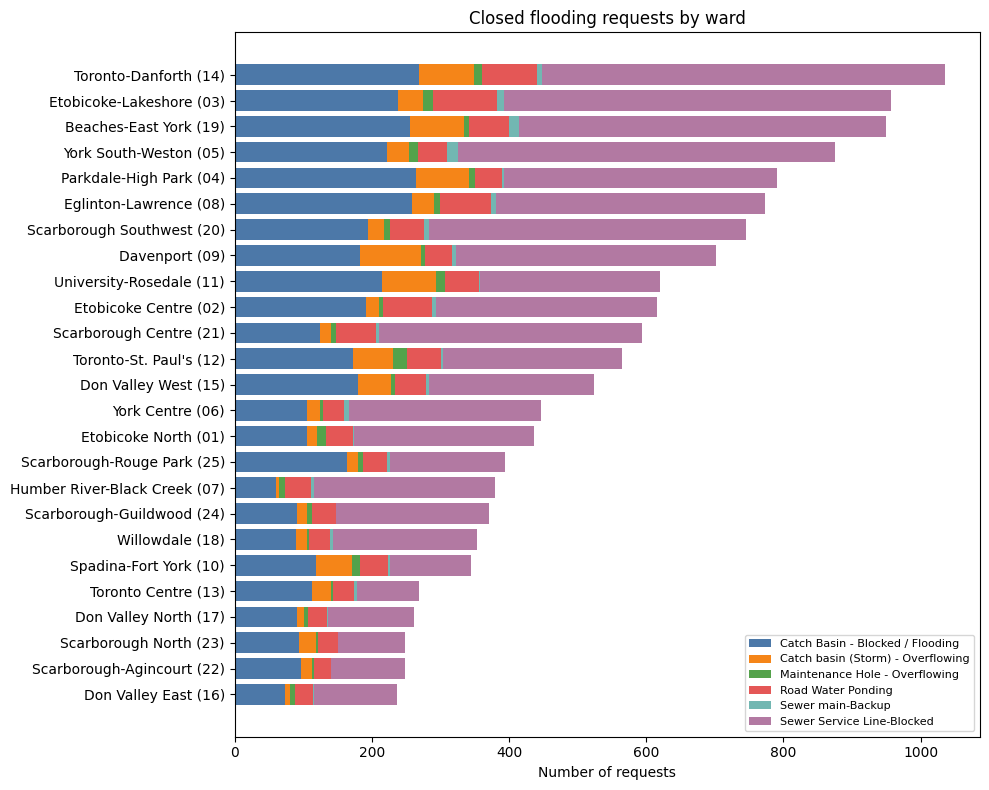

Service Request Type,rank,Ward,Catch Basin - Blocked / Flooding,Catch basin (Storm) - Overflowing,Maintenance Hole - Overflowing,Road Water Ponding,Sewer main-Backup,Sewer Service Line-Blocked,total
0,1,Toronto-Danforth (14),268,81,12,80,7,587,1035
1,2,Etobicoke-Lakeshore (03),238,37,14,94,10,564,957
2,3,Beaches-East York (19),255,79,8,58,14,536,950
3,4,York South-Weston (05),222,32,13,43,16,550,876
4,5,Parkdale-High Park (04),265,76,10,39,2,399,791
5,6,Eglinton-Lawrence (08),258,33,9,74,7,392,773
6,7,Scarborough Southwest (20),194,24,8,50,7,463,746
7,8,Davenport (09),182,90,5,40,5,380,702
8,9,University-Rosedale (11),215,78,14,49,1,263,620
9,10,Etobicoke Centre (02),191,19,6,72,6,322,616


In [47]:
request_types = labels["Service type to keep"].tolist()
colors = ["#4C78A8", "#F58518", "#54A24B", "#E45756", "#72B7B2", "#B279A2"]

ward_counts = (
    sr_2019_flood.groupby(["Ward", "Service Request Type"])
    .size()
    .unstack("Service Request Type", fill_value=0)
    .reindex(columns=request_types, fill_value=0)
)
ward_counts["total"] = ward_counts.sum(axis=1)
ward_totals = ward_counts.reset_index().sort_values(["total", "Ward"], ascending=[False, True])
ward_totals["rank"] = ward_totals["total"].rank(method="min", ascending=False).astype(int)
ward_totals = ward_totals[["rank", "Ward", *request_types, "total"]].reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 8))
plot_order = ward_totals
shares = plot_order[request_types].div(plot_order["total"], axis=0) * 100
left = None
for request_type, color in zip(request_types, colors):
    values = shares[request_type].to_numpy()
    ax.barh(
        plot_order["Ward"],
        values,
        left=0 if left is None else left,
        color=color,
        label=request_type,
    )
    left = values if left is None else left + values
ax.set_xlim(0, 100)
ax.set_xlabel("Share of requests (%)")
ax.set_title("Closed flooding requests by ward")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2, fontsize=8, frameon=False)
fig.tight_layout()
plt.show()

ward_totals

## SR 2019 to 2026(Nov)

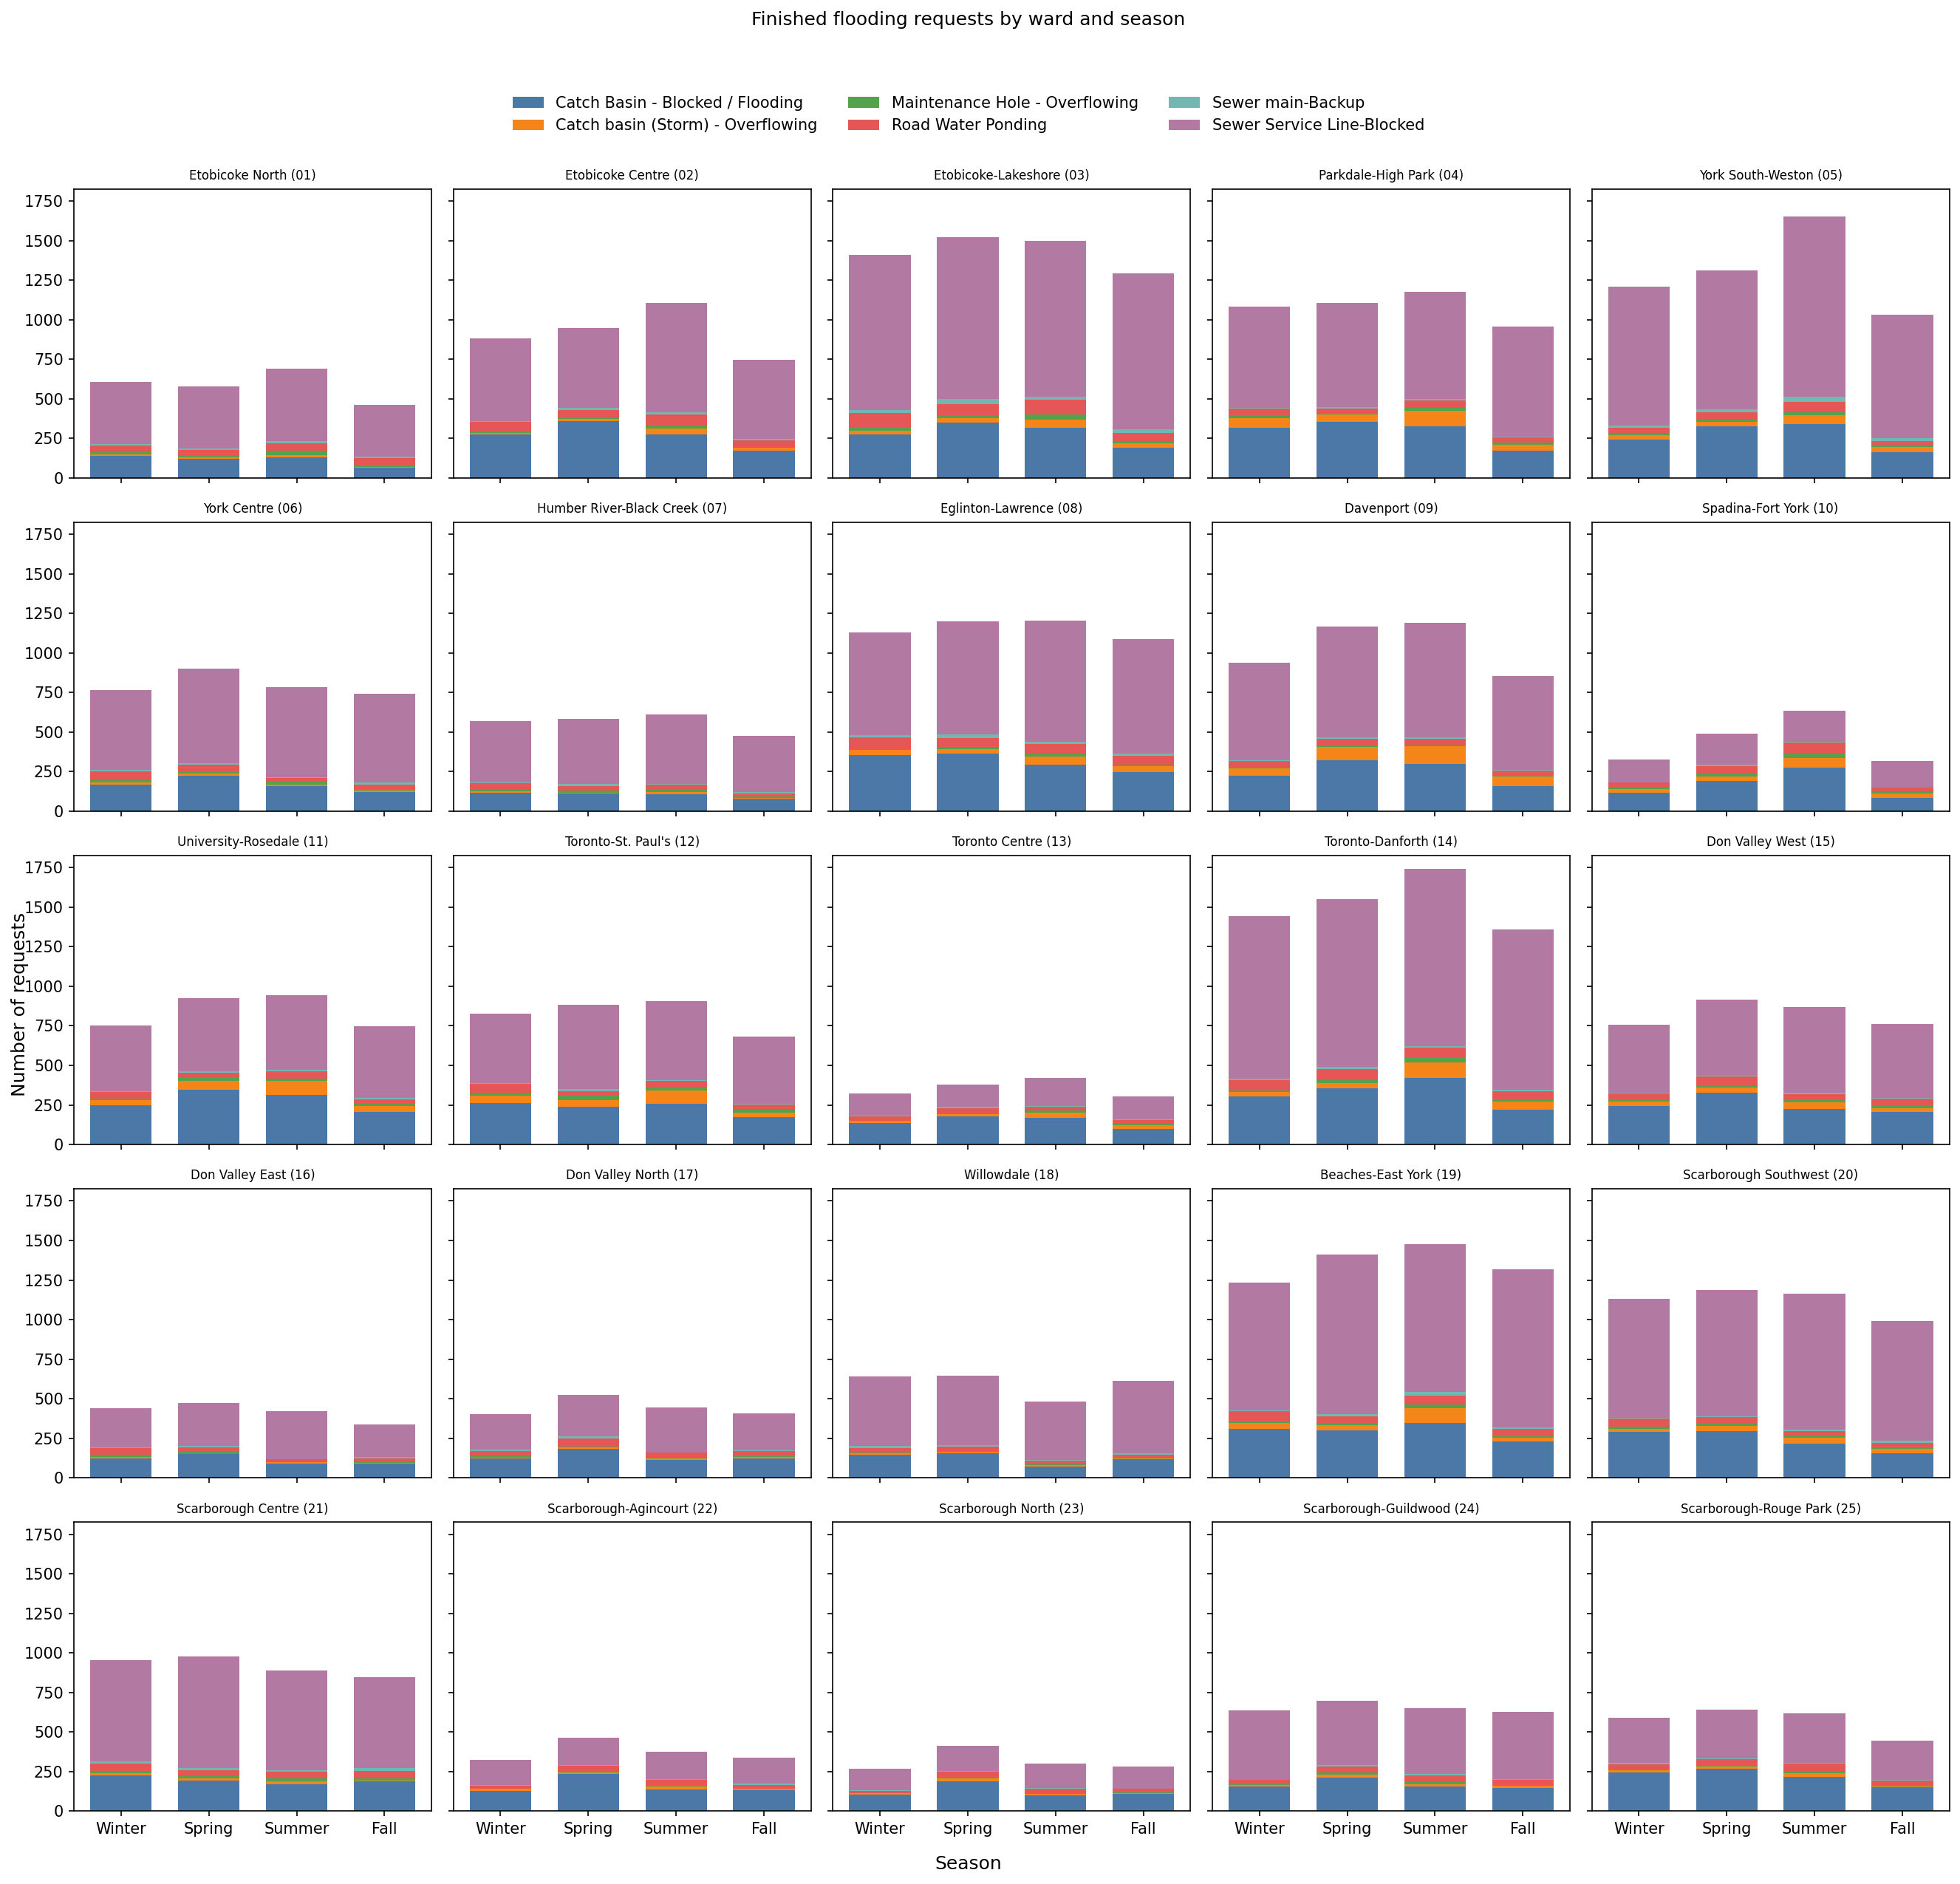

In [102]:
import subprocess
import sys
from pathlib import Path

from IPython.display import Image, display

data_dir_candidates = [
    Path.cwd(),
    Path.cwd() / "311 service request",
]
data_dir = next(
    path for path in data_dir_candidates if (path / "plot_flood_requests_by_season.py").exists()
)
years = range(2019, 2027)
csv_paths = [data_dir / f"SR{year}.csv" for year in years]
output = data_dir / "flood_requests_by_season.png"

completed = subprocess.run(
    [
        sys.executable,
        str(data_dir / "plot_flood_requests_by_season.py"),
        *map(str, csv_paths),
        "--labels",
        str(data_dir / "311_SR_label_to_keep.csv"),
        "-o",
        str(output),
    ],
    check=False,
    capture_output=True,
    text=True,
)
if completed.returncode != 0:
    print(completed.stdout)
    print(completed.stderr)
    raise RuntimeError(completed.stderr or f"Script exited with status {completed.returncode}")
display(Image(filename=str(output)))

81,783 finished flooding requests from SR2019.csv, SR2020.csv, SR2021.csv, SR2022.csv, SR2023.csv, SR2024.csv, SR2025.csv, SR2026.csv
Saved /Users/Doggy/Documents/wai hackathon/urban basement flooding /311 service request/flood_requests_by_ward_season_year.png



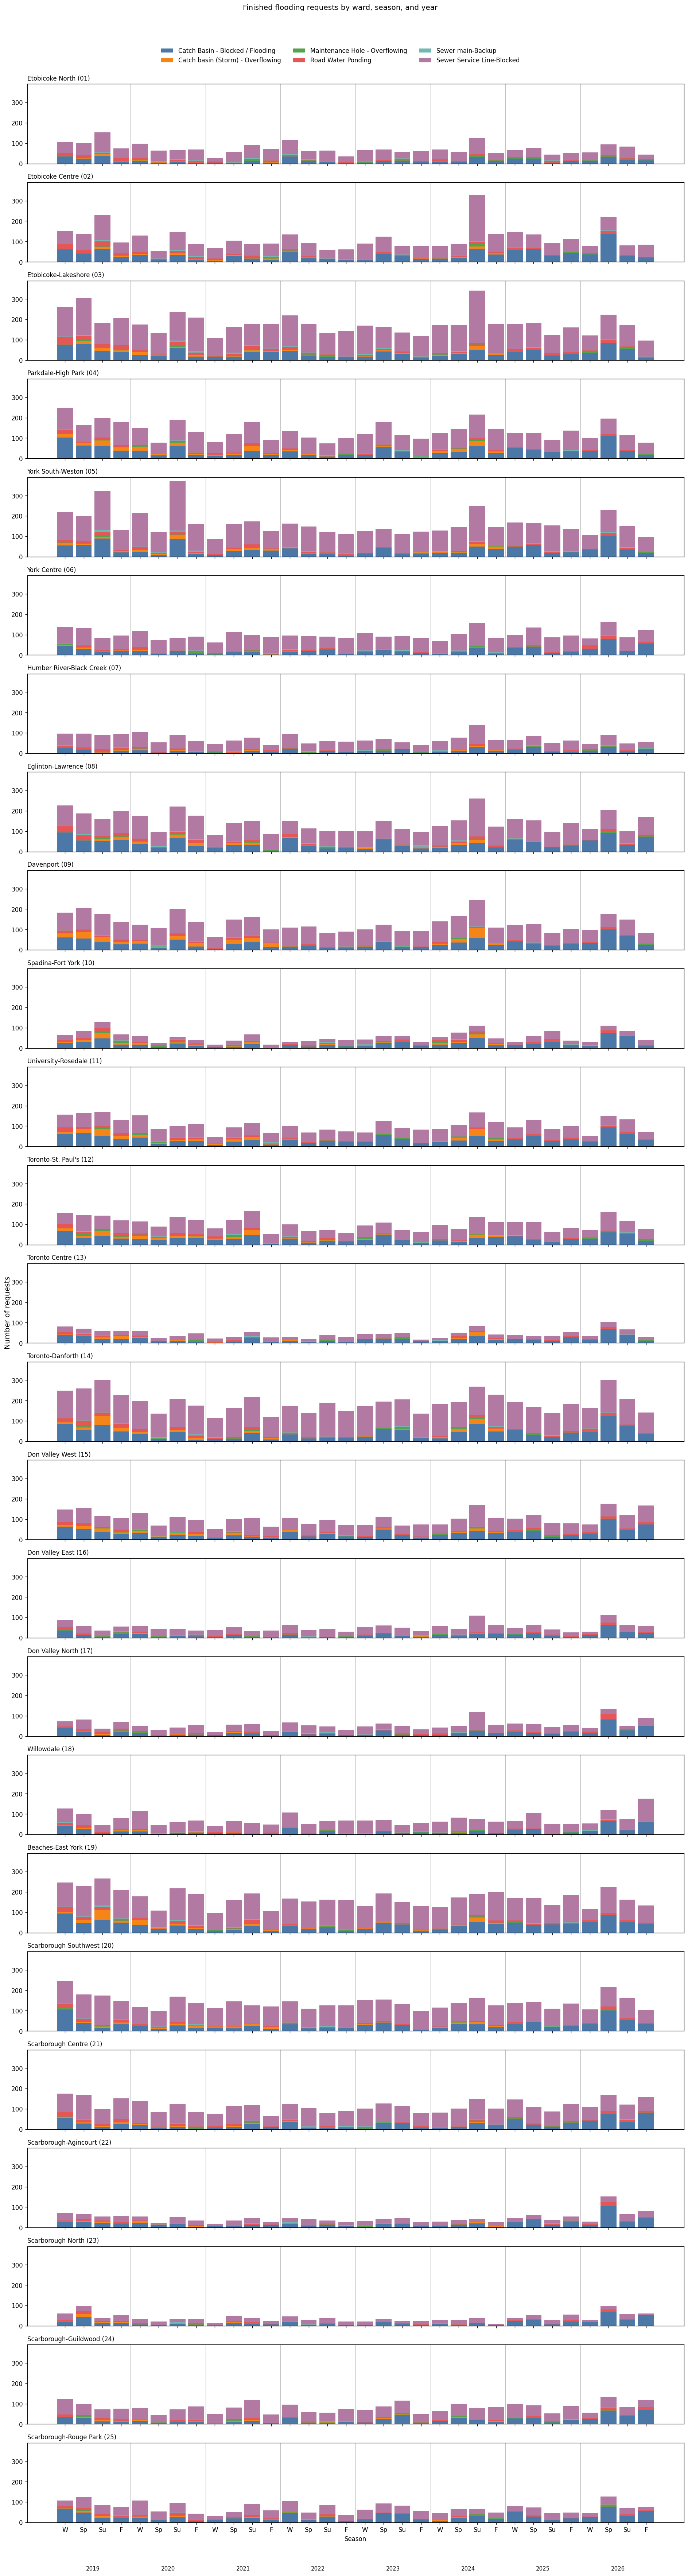

In [103]:
import subprocess
import sys
from pathlib import Path

from IPython.display import Image, display

data_dir_candidates = [
    Path.cwd(),
    Path.cwd() / "311 service request",
]
data_dir = next(
    path for path in data_dir_candidates if (path / "plot_flood_requests_by_season.py").exists()
)
years = range(2019, 2027)
csv_paths = [data_dir / f"SR{year}.csv" for year in years]
output_by_year = data_dir / "flood_requests_by_ward_season_year.png"

completed = subprocess.run(
    [
        sys.executable,
        str(data_dir / "plot_flood_requests_by_season.py"),
        *map(str, csv_paths),
        "--labels",
        str(data_dir / "311_SR_label_to_keep.csv"),
        "--by-year",
        "-o",
        str(output_by_year),
    ],
    check=False,
    capture_output=True,
    text=True,
)
if completed.returncode != 0:
    print(completed.stdout)
    print(completed.stderr)
    raise RuntimeError(completed.stderr or f"Script exited with status {completed.returncode}")
print(completed.stdout)
display(Image(filename=str(output_by_year)))

In [104]:
completed

CompletedProcess(args=['/Library/Developer/CommandLineTools/usr/bin/python3', '/Users/Doggy/Documents/wai hackathon/urban basement flooding /311 service request/plot_flood_requests_by_season.py', '/Users/Doggy/Documents/wai hackathon/urban basement flooding /311 service request/SR2019.csv', '/Users/Doggy/Documents/wai hackathon/urban basement flooding /311 service request/SR2020.csv', '/Users/Doggy/Documents/wai hackathon/urban basement flooding /311 service request/SR2021.csv', '/Users/Doggy/Documents/wai hackathon/urban basement flooding /311 service request/SR2022.csv', '/Users/Doggy/Documents/wai hackathon/urban basement flooding /311 service request/SR2023.csv', '/Users/Doggy/Documents/wai hackathon/urban basement flooding /311 service request/SR2024.csv', '/Users/Doggy/Documents/wai hackathon/urban basement flooding /311 service request/SR2025.csv', '/Users/Doggy/Documents/wai hackathon/urban basement flooding /311 service request/SR2026.csv', '--labels', '/Users/Doggy/Documents/

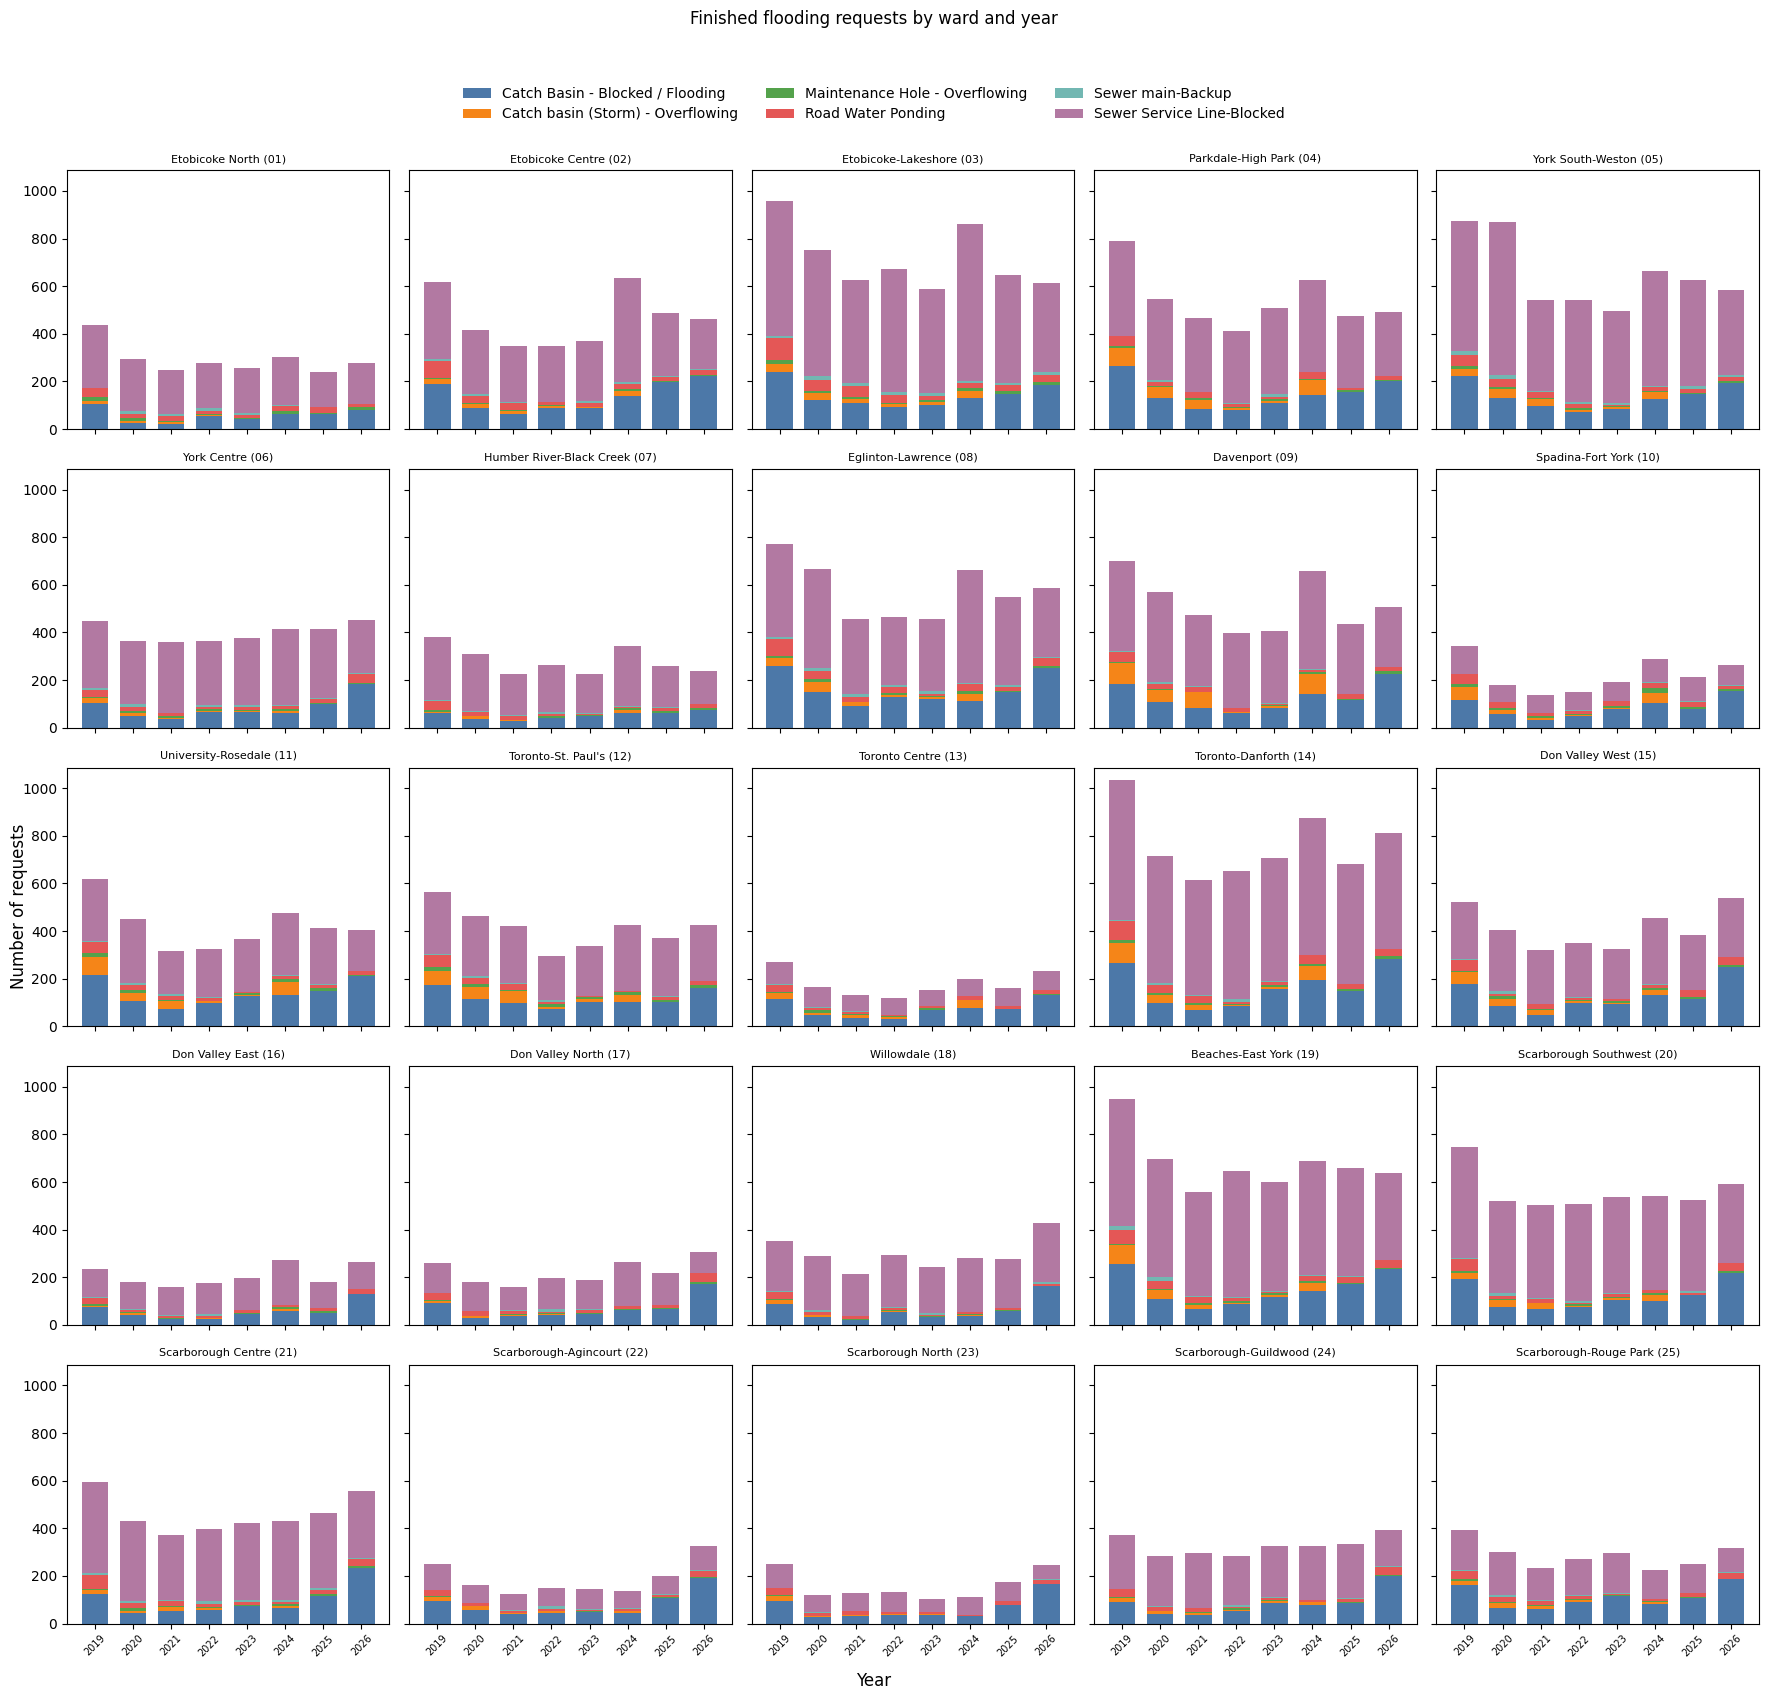

81,783 finished flooding requests, 2019–2025
Saved /Users/Doggy/Documents/wai hackathon/urban basement flooding /311 service request/flood_requests_by_ward_year.png


In [105]:
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

data_dir_candidates = [
    Path.cwd(),
    Path.cwd() / "311 service request",
]
data_dir = next(path for path in data_dir_candidates if (path / "SR2019.csv").exists())
label_path = data_dir / "311_SR_label_to_keep.csv"
request_types = pd.read_csv(label_path)["Service type to keep"].tolist()
years = list(range(2019, 2027))

frames = []
for year in years:
    path = data_dir / f"SR{year}.csv"
    for encoding in ("utf-8", "cp1252"):
        try:
            year_df = pd.read_csv(
                path,
                usecols=["Creation Date", "Status", "Ward", "Service Request Type"],
                encoding=encoding,
            )
            break
        except UnicodeDecodeError:
            continue
    created = pd.to_datetime(year_df["Creation Date"])
    # 311 renamed the finished status from Closed to Completed in 2022.
    finished = (
        ((created.dt.year < 2022) & (year_df["Status"] == "Closed"))
        | ((created.dt.year >= 2022) & (year_df["Status"] == "Completed"))
    )
    kept = year_df[year_df["Service Request Type"].isin(request_types) & finished].copy()
    kept["year"] = created.loc[kept.index].dt.year
    frames.append(kept)

flood_years = pd.concat(frames, ignore_index=True)
flood_years = flood_years[flood_years["Ward"].str.contains(r"\(\d+\)", na=False)]
yearly_counts = (
    flood_years.groupby(["Ward", "year", "Service Request Type"])
    .size()
    .unstack("Service Request Type", fill_value=0)
    .reindex(columns=request_types, fill_value=0)
)


def ward_number(name):
    return int(name.rsplit("(", 1)[1].rstrip(")"))


wards = sorted(flood_years["Ward"].unique(), key=ward_number)
colors = ["#4C78A8", "#F58518", "#54A24B", "#E45756", "#72B7B2", "#B279A2"]

fig, axes = plt.subplots(5, 5, figsize=(18, 16), sharex=True, sharey=True)
axes = axes.ravel()

for ax, ward in zip(axes, wards):
    ward_counts = yearly_counts.loc[ward].reindex(years, fill_value=0)
    bottom = None
    for request_type, color in zip(request_types, colors):
        values = ward_counts[request_type].to_numpy()
        ax.bar(
            years,
            values,
            bottom=0 if bottom is None else bottom,
            color=color,
            width=0.7,
            label=request_type,
        )
        bottom = values if bottom is None else bottom + values
    ax.set_title(ward, fontsize=8)
    ax.set_xticks(years)
    ax.tick_params(axis="x", labelrotation=45, labelsize=7)

for ax in axes[len(wards) :]:
    ax.axis("off")

handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    legend_labels,
    loc="upper center",
    ncol=3,
    frameon=False,
    bbox_to_anchor=(0.5, 1.02),
)
fig.suptitle("Finished flooding requests by ward and year", y=1.06)
fig.supxlabel("Year")
fig.supylabel("Number of requests")
fig.tight_layout()
output = data_dir / "flood_requests_by_ward_year.png"
fig.savefig(output, dpi=150, bbox_inches="tight")
plt.show()
print(f"{len(flood_years):,} finished flooding requests, 2019–2025")
print(f"Saved {output.resolve()}")


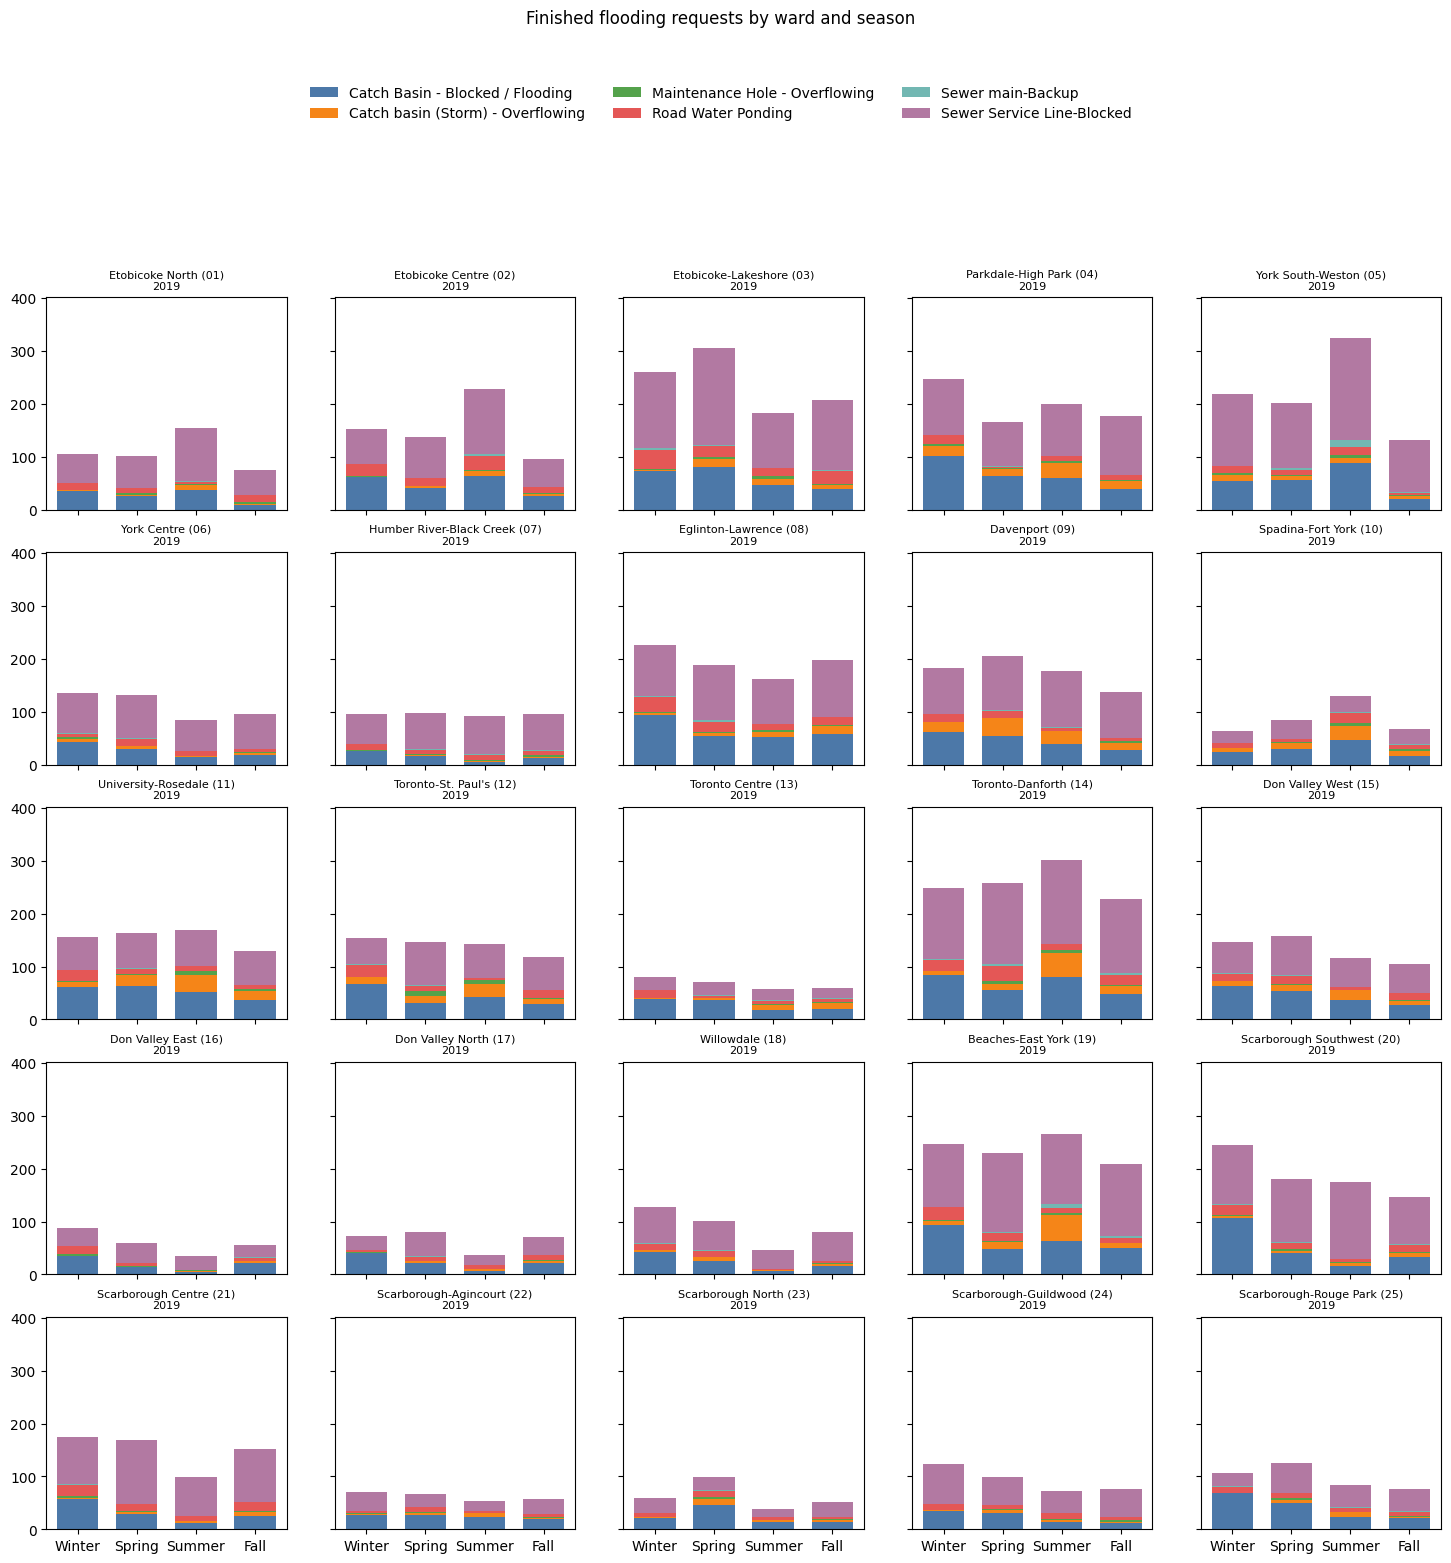

In [106]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import HTML
from matplotlib.animation import FuncAnimation
from pathlib import Path

data_dir_candidates = [
    Path.cwd(),
    Path.cwd() / "311 service request",
]
data_dir = next(path for path in data_dir_candidates if (path / "SR2019.csv").exists())
request_types = pd.read_csv(data_dir / "311_SR_label_to_keep.csv")["Service type to keep"].tolist()
years = list(range(2019, 2027))
seasons = ["Winter", "Spring", "Summer", "Fall"]
season_by_month = {
    12: "Winter",
    1: "Winter",
    2: "Winter",
    3: "Spring",
    4: "Spring",
    5: "Spring",
    6: "Summer",
    7: "Summer",
    8: "Summer",
    9: "Fall",
    10: "Fall",
    11: "Fall",
}
colors = ["#4C78A8", "#F58518", "#54A24B", "#E45756", "#72B7B2", "#B279A2"]

frames = []
for year in years:
    path = data_dir / f"SR{year}.csv"
    for encoding in ("utf-8", "cp1252"):
        try:
            year_df = pd.read_csv(
                path,
                usecols=["Creation Date", "Status", "Ward", "Service Request Type"],
                encoding=encoding,
            )
            break
        except UnicodeDecodeError:
            continue
    created = pd.to_datetime(year_df["Creation Date"])
    finished = (
        ((created.dt.year < 2022) & (year_df["Status"] == "Closed"))
        | ((created.dt.year >= 2022) & (year_df["Status"] == "Completed"))
    )
    kept = year_df[year_df["Service Request Type"].isin(request_types) & finished].copy()
    kept["year"] = created.loc[kept.index].dt.year
    kept["season"] = created.loc[kept.index].dt.month.map(season_by_month)
    frames.append(kept)

flood = pd.concat(frames, ignore_index=True)
flood = flood[flood["Ward"].str.contains(r"\(\d+\)", na=False)]


def ward_number(name):
    return int(name.rsplit("(", 1)[1].rstrip(")"))


wards = sorted(flood["Ward"].unique(), key=ward_number)
season_year_counts = (
    flood.groupby(["Ward", "year", "season", "Service Request Type"])
    .size()
    .unstack("Service Request Type", fill_value=0)
    .reindex(columns=request_types, fill_value=0)
)
slots = pd.MultiIndex.from_product([wards, years, seasons], names=["Ward", "year", "season"])
season_year_counts = season_year_counts.reindex(slots, fill_value=0).sort_index()
ymax = season_year_counts.sum(axis=1).max() * 1.08

fig, axes = plt.subplots(5, 5, figsize=(18, 16), sharex=True, sharey=True)
axes = axes.ravel()


def draw(year):
    for legend in list(fig.legends):
        legend.remove()
    for ax, ward in zip(axes, wards):
        ax.clear()
        ward_counts = season_year_counts.loc[(ward, int(year))].reindex(seasons, fill_value=0)
        bottom = None
        for request_type, color in zip(request_types, colors):
            values = ward_counts[request_type].to_numpy()
            ax.bar(
                seasons,
                values,
                bottom=0 if bottom is None else bottom,
                color=color,
                width=0.7,
                label=request_type,
            )
            bottom = values if bottom is None else bottom + values
        ax.set_title(f"{ward}\n{int(year)}", fontsize=8)
        ax.set_ylim(0, ymax)
    handles, legend_labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles,
        legend_labels,
        loc="upper center",
        ncol=3,
        frameon=False,
        bbox_to_anchor=(0.5, 1.02),
    )
    fig.suptitle("Finished flooding requests by ward and season", y=1.06)


anim = FuncAnimation(fig, draw, frames=years, interval=1200, repeat=True)
HTML(anim.to_jshtml())


In [ ]:
import matplotlib.pyplot as plt

ward_id =2
seasons = ["Winter", "Spring", "Summer", "Fall"]
season_by_month = {
    12: "Winter",
    1: "Winter",
    2: "Winter",
    3: "Spring",
    4: "Spring",
    5: "Spring",
    6: "Summer",
    7: "Summer",
    8: "Summer",
    9: "Fall",
    10: "Fall",
    11: "Fall",
}

ward_name = next(name for name in sr_2019_flood["Ward"].unique() if ward_number(name) == ward_id)
ward_rows = sr_2019_flood[sr_2019_flood["Ward"] == ward_name].copy()
ward_rows["FSA"] = ward_rows["First 3 Chars of Postal Code"].fillna("Unknown")
ward_rows["season"] = ward_rows["month"].map(season_by_month)

fsa_order = ward_rows["FSA"].value_counts().index.tolist()
fsa_counts = (
    ward_rows.groupby(["season", "FSA"])
    .size()
    .unstack("FSA", fill_value=0)
    .reindex(index=seasons, columns=fsa_order, fill_value=0)
)

colors = plt.cm.tab10.colors
fig, ax = plt.subplots(figsize=(8, 5))
bottom = None
for fsa, color in zip(fsa_order, colors):
    values = fsa_counts[fsa].to_numpy()
    ax.bar(
        seasons,
        values,
        bottom=0 if bottom is None else bottom,
        color=color,
        width=0.7,
        label=fsa,
    )
    bottom = values if bottom is None else bottom + values

ax.set_xlabel("Season")
ax.set_ylabel("Closed flooding requests")
ax.set_title(f"{ward_name}: seasonal requests by FSA, 2019")
ax.legend(title="FSA", ncol=2, frameon=False)
fig.tight_layout()
plt.show()
